In [1]:
%% MIT 18.03 Lecture 38: Nonlinear Pendulum, Phugoid Flight Mode & Tacoma Bridge Flutter
% Description: Simulates three classic engineering linearization & stability problems:
%              1) Nonlinear Damped Pendulum: theta'' + b*theta' + k*sin(theta) = 0,
%                 showing multi-basin attractors at 2*n*pi and saddles at (2n+1)*pi.
%              2) Airplane Phugoid Oscillation: Boeing 747 (v0=260 m/s, F/mg=0.27) vs.
%                 F-15 Fighter (v0=838 m/s, F/mg=0.67) using Control System Toolbox 'ss' & 'initial'.
%              3) Tacoma Narrows Bridge Aeroelastic Anti-Damping: theta'' + (b - c(v))*theta' + wn^2*theta = 0.
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, pole, damp).
%
% % MBD Concept Mapping: Demonstrates multi-equilibrium phase portraits, dimensionless flight dynamics
% %                      parameterization (wn, zeta), and aeroelastic instability via pole migration into RHP.


clear; clc; close all;


%% =========================================================================
%% Part 1: Nonlinear Damped Pendulum Phase Portrait (Lecture Section [1])
%% =========================================================================
% Equation: theta'' + b*theta' + k*sin(theta) = 0  <--->  x' = y, y' = -k*sin(x) - b*y
k_pend = 4.0;   % g/L (rad/s^2)
b_pend = 0.4;   % c/m damping coefficient (1/s)


% Local Linearized State-Space Models via Control System Toolbox
J_down = [0, 1; -k_pend, -b_pend]; % At x = 0, 2*pi (Straight down: Stable Spiral)
J_up   = [0, 1; +k_pend, -b_pend]; % At x = +/- pi   (Straight up: Unstable Saddle)


sys_pend_down = ss(J_down, zeros(2,1), eye(2), zeros(2,1));
sys_pend_up   = ss(J_up,   zeros(2,1), eye(2), zeros(2,1));


fprintf('=== MIT 18.03 Lecture 38 Engineering Linearization Diagnostics ===\n');

=== MIT 18.03 Lecture 38 Engineering Linearization Diagnostics ===

In [2]:
fprintf('1) Nonlinear Pendulum Equilibria (k = %.1f, b = %.1f):\n', k_pend, b_pend);

1) Nonlinear Pendulum Equilibria (k = 4.0, b = 0.4):

In [3]:
p_down = pole(sys_pend_down);
p_up   = pole(sys_pend_up);
fprintf('   Straight Down (0, 2pi) Poles : %+.3f %+.3fi (Stable Spiral Attractor)\n', ...
        real(p_down(1)), abs(imag(p_down(1))));

   Straight Down (0, 2pi) Poles : -0.200 +1.990i (Stable Spiral Attractor)

In [4]:
fprintf('   Straight Up (+/- pi) Poles   : %+.3f, %+.3f (Unstable Saddle Point)\n\n', ...
        p_up(1), p_up(2));

   Straight Up (+/- pi) Poles   : +1.810, -2.210 (Unstable Saddle Point)

In [5]:


%% =========================================================================
%% Part 2: Airplane Phugoid Oscillation: Boeing 747 vs. F-15 (Section [2])
%% =========================================================================
% State Matrix: A = [ -2*F/(m*v0),  -g/v0 ;
%                      2*g/v0    ,    0   ]
% Note: thrust-to-weight ratio T_W = F / (m*g), so 2*F/(m*v0) = 2 * T_W * (g / v0)
g_acc = 9.81;


% Aircraft 1: Boeing 747 (v0 = 260 m/s, F/mg = 0.27)
v0_747 = 260.0; TW_747 = 0.27;
A_747  = [-2 * TW_747 * (g_acc / v0_747), -g_acc / v0_747;
           2 * g_acc / v0_747,             0             ];
sys_747 = ss(A_747, zeros(2,1), eye(2), zeros(2,1));


% Aircraft 2: F-15 Eagle (v0 = 838 m/s, F/mg = 0.67)
v0_f15 = 838.0; TW_f15 = 0.67;
A_f15  = [-2 * TW_f15 * (g_acc / v0_f15), -g_acc / v0_f15;
           2 * g_acc / v0_f15,             0             ];
sys_f15 = ss(A_f15, zeros(2,1), eye(2), zeros(2,1));


wn_747 = sqrt(2) * g_acc / v0_747; zeta_747 = TW_747 / sqrt(2); T_747 = 2*pi / wn_747;
wn_f15 = sqrt(2) * g_acc / v0_f15; zeta_f15 = TW_f15 / sqrt(2); T_f15 = 2*pi / wn_f15;


fprintf('2) Phugoid Longitudinal Flight Dynamics:\n');

2) Phugoid Longitudinal Flight Dynamics:

In [6]:
fprintf('   Boeing 747 (v0=260 m/s, F/mg=0.27): wn=%.4f rad/s, Period=%.1f s, zeta=%.3f\n', ...
        wn_747, T_747, zeta_747);

   Boeing 747 (v0=260 m/s, F/mg=0.27): wn=0.0534 rad/s, Period=117.8 s, zeta=0.191

In [7]:
fprintf('   F-15 Eagle (v0=838 m/s, F/mg=0.67): wn=%.4f rad/s, Period=%.1f s, zeta=%.3f\n\n', ...
        wn_f15, T_f15, zeta_f15);

   F-15 Eagle (v0=838 m/s, F/mg=0.67): wn=0.0166 rad/s, Period=379.5 s, zeta=0.474

In [8]:


%% =========================================================================
%% Part 3: Tacoma Narrows Bridge Anti-Damping Instability (Section [3])
%% =========================================================================
% Equation: theta'' + (b - c(v))*theta' + wn^2 * theta = 0
wn_bridge = 1.5; % Torsional natural frequency (rad/s)
b_struct  = 0.2; % Structural mechanical damping
c_wind_safe     = -0.15; % Low wind speed: c(v) < 0 increases damping
c_wind_disaster = +0.35; % High wind speed: c(v) > b causes negative damping (Anti-damping!)


sys_bridge_safe     = ss([0, 1; -wn_bridge^2, -(b_struct - c_wind_safe)], zeros(2,1), [1, 0], 0);
sys_bridge_disaster = ss([0, 1; -wn_bridge^2, -(b_struct - c_wind_disaster)], zeros(2,1), [1, 0], 0);


fprintf('3) Tacoma Narrows Bridge Aeroelasticity (b = %.2f):\n', b_struct);

3) Tacoma Narrows Bridge Aeroelasticity (b = 0.20):

In [9]:
fprintf('   Low Wind (c(v) = %+.2f)  --> Effective Damping = %+.2f (Stable Decay)\n', ...
        c_wind_safe, b_struct - c_wind_safe);

   Low Wind (c(v) = -0.15)  --> Effective Damping = +0.35 (Stable Decay)

In [10]:
fprintf('   Storm Wind (c(v) = %+.2f)--> Effective Damping = %+.2f (Anti-Damping Disaster!)\n', ...
        c_wind_disaster, b_struct - c_wind_disaster);

   Storm Wind (c(v) = +0.35)--> Effective Damping = -0.15 (Anti-Damping Disaster!)

In [11]:
fprintf('==================================================================\n');


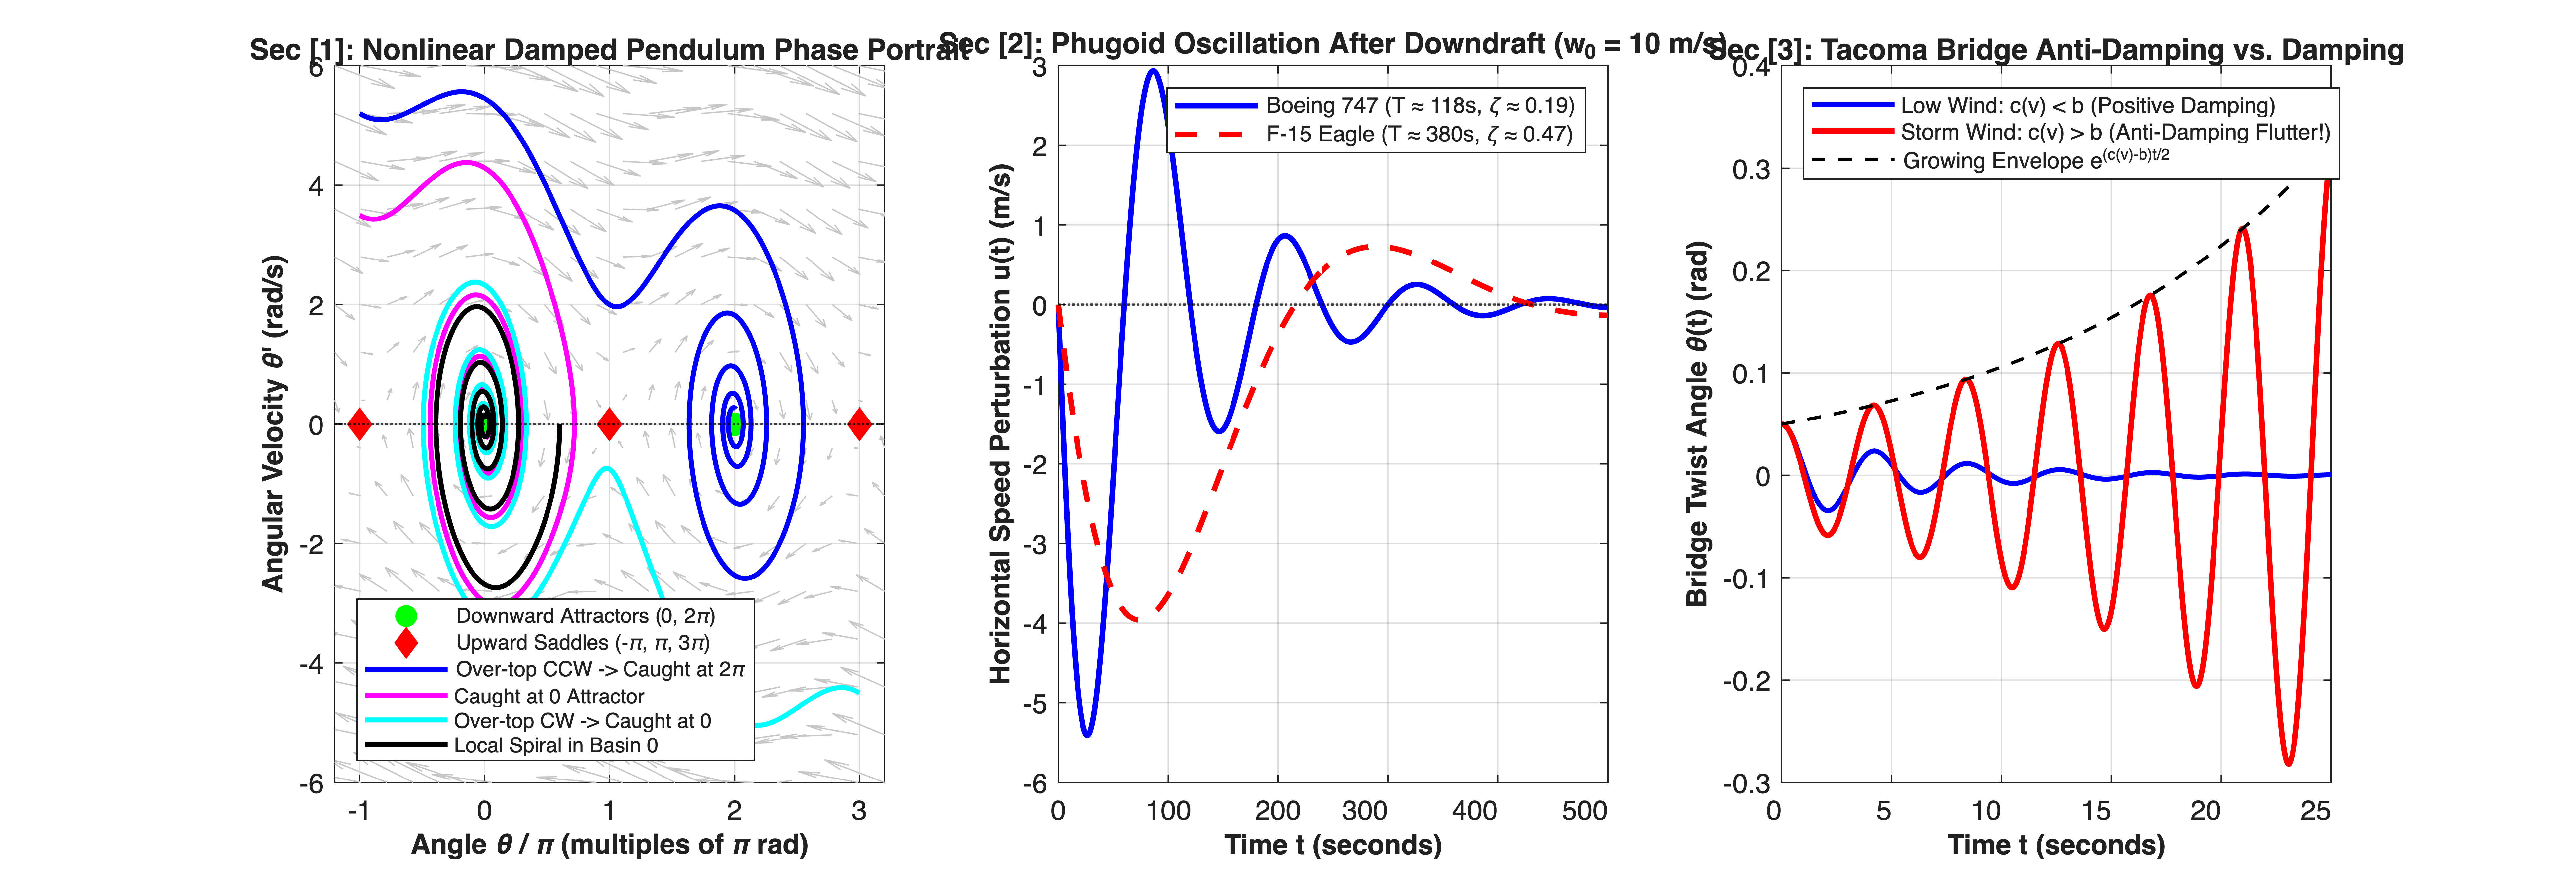

In [12]:


%% =========================================================================
%% Part 4: Three-Panel Engineering Visualization
%% =========================================================================
figure('Color', [1 1 1], 'Position', [50, 60, 1320, 450]);


% Subplot 1: Nonlinear Pendulum Phase Plane (Over-the-top swings & Basin capture)
subplot(1, 3, 1);
hold on; grid on; box on;
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


[Xp, Yp] = meshgrid(linspace(-1.2*pi, 3.2*pi, 22), linspace(-6, 6, 16));
Up = Yp; Vp = -k_pend * sin(Xp) - b_pend * Yp;
quiver(Xp/pi, Yp, Up, Vp, 'Color', [0.78 0.78 0.78], 'HandleVisibility', 'off');


% Plot Equilibria: Attractors at 0, 2*pi; Saddles at -pi, pi, 3*pi
plot([0, 2], [0, 0], 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 8, ...
     'DisplayName', 'Downward Attractors (0, 2\pi)');
plot([-1, 1, 3], [0, 0, 0], 'rd', 'MarkerFaceColor', 'r', 'MarkerSize', 8, ...
     'DisplayName', 'Upward Saddles (-\pi, \pi, 3\pi)');


% Simulate trajectories: one swinging over the top from left, one from right, one local
ode_pend = @(t, U) [U(2); -k_pend * sin(U(1)) - b_pend * U(2)];
t_pend = linspace(0, 16, 1000);
ic_pend = [-pi, 5.2;   -pi, 3.5;   3*pi, -4.5;   0.6*pi, 0]';
colors_p = {'b-', 'm-', 'c-', 'k-'};
labels_p = {'Over-top CCW -> Caught at 2\pi', 'Caught at 0 Attractor', ...
            'Over-top CW -> Caught at 0', 'Local Spiral in Basin 0'};


for k = 1:size(ic_pend, 2)
    [~, U_p] = ode45(ode_pend, t_pend, ic_pend(:, k));
    plot(U_p(:, 1)/pi, U_p(:, 2), colors_p{k}, 'LineWidth', 1.8, 'DisplayName', labels_p{k});
end


xlabel('Angle \theta / \pi (multiples of \pi rad)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Angular Velocity \theta'' (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [1]: Nonlinear Damped Pendulum Phase Portrait', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'southwest', 'FontSize', 7.5);
xlim([-1.2, 3.2]); ylim([-6, 6]);


% Subplot 2: Phugoid Oscillation Time Response (Boeing 747 vs F-15)
% Initial downdraft disturbance: u(0) = 0, w(0) = 10 m/s
subplot(1, 3, 2);
hold on; grid on; box on;
t_phugoid = linspace(0, 500, 1000);
[Y_747, ~] = initial(sys_747, [0; 10], t_phugoid);
[Y_f15, ~] = initial(sys_f15, [0; 10], t_phugoid);


plot(t_phugoid, Y_747(:, 1), 'b-', 'LineWidth', 2.0, ...
     'DisplayName', sprintf('Boeing 747 (T\\approx118s, \\zeta\\approx0.19)'));
plot(t_phugoid, Y_f15(:, 1), 'r--', 'LineWidth', 2.0, ...
     'DisplayName', sprintf('F-15 Eagle (T\\approx380s, \\zeta\\approx0.47)'));
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Horizontal Speed Perturbation u(t) (m/s)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [2]: Phugoid Oscillation After Downdraft (w_0 = 10 m/s)', ...
      'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8);
xlim([0, 500]);


% Subplot 3: Tacoma Narrows Bridge Anti-Damping Instability
subplot(1, 3, 3);
hold on; grid on; box on;
t_bridge = linspace(0, 25, 800);
[theta_safe, ~]     = initial(sys_bridge_safe,     [0.05; 0], t_bridge);
[theta_disaster, ~] = initial(sys_bridge_disaster, [0.05; 0], t_bridge);


plot(t_bridge, theta_safe, 'b-', 'LineWidth', 1.8, ...
     'DisplayName', 'Low Wind: c(v) < b (Positive Damping)');
plot(t_bridge, theta_disaster, 'r-', 'LineWidth', 2.0, ...
     'DisplayName', 'Storm Wind: c(v) > b (Anti-Damping Flutter!)');
plot(t_bridge, 0.05 * exp((c_wind_disaster - b_struct)/2 * t_bridge), 'k--', ...
     'LineWidth', 1.2, 'DisplayName', 'Growing Envelope e^{(c(v)-b)t/2}');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Bridge Twist Angle \theta(t) (rad)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [3]: Tacoma Bridge Anti-Damping vs. Damping', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
xlim([0, 25]);